# Diabetes Readmission: Focused Exploratory Analysis

## Project question
Can information available at hospital discharge help identify encounters followed by an inpatient readmission within 30 days?

The dataset contains encounter records from 130 US hospitals during 1999-2008. The original outcome is `readmitted`: `<30`, `>30`, or `NO`. Our positive class is `<30`.

Source: [UCI Machine Learning Repository - Diabetes 130-US Hospitals](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008).

This notebook keeps the raw data unchanged. It focuses on evidence that informs the cohort definition, missing-value policy, and initial feature candidates; it does not train a model yet.


## Load the raw encounter data

Read the CSV without automatic NA conversion so that raw tokens such as `?` and `None` can be examined separately. The payer code is kept as a string because it is categorical, not a numeric measurement.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

data_path = next(
    (
        folder / "diabetic_data.csv"
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "diabetic_data.csv").is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError("Could not find diabetic_data.csv in the current folder or a parent folder.")

raw_df = pd.read_csv(
    data_path,
    keep_default_na=False,
    low_memory=False,
    dtype={"payer_code": "string"},
)
print(f"Loaded {raw_df.shape[0]:,} encounters and {raw_df.shape[1]} columns from {data_path.name}.")
display(raw_df[["encounter_id", "patient_nbr", "age", "gender", "readmitted"]].head(3))


Loaded 101,766 encounters and 50 columns from diabetic_data.csv.


,encounter_id,patient_nbr,age,gender,readmitted
0,2278392,8222157,[0-10),Female,NO
1,149190,55629189,[10-20),Female,>30
2,64410,86047875,[20-30),Female,NO


## 1. What is one row, and do patients repeat?

Each row represents an encounter, but a patient may have multiple encounters. We need the counts both to interpret the unit of analysis and to plan a patient-grouped train/test split.


In [2]:
encounters_per_patient = raw_df.groupby("patient_nbr")["encounter_id"].size()
repeated_patients = encounters_per_patient[encounters_per_patient > 1]

overview = pd.Series(
    {
        "Encounter rows": len(raw_df),
        "Columns": raw_df.shape[1],
        "Unique encounter IDs": raw_df["encounter_id"].nunique(),
        "Unique patients": raw_df["patient_nbr"].nunique(),
        "Patients with multiple encounters": len(repeated_patients),
        "Maximum encounters for one patient": int(encounters_per_patient.max()),
    },
    name="Value",
).to_frame()
display(overview)


,Value
Encounter rows,101766
Columns,50
Unique encounter IDs,101766
Unique patients,71518
Patients with multiple encounters,16773
Maximum encounters for one patient,40


There are 101,766 rows and 71,518 patients; 16,773 patients have multiple encounters, with a maximum of 40. An encounter is therefore the row-level unit, but later evaluation must keep a patient's encounters in the same split. `encounter_id` and `patient_nbr` are identifiers, not model inputs.

## 2. Which raw values may indicate missing or unavailable information?

Count `?`, literal `None`, and blank cells separately. They do not all have the same meaning, so this is a marker audit rather than an imputation step.


,Question mark count,Literal None count,Blank cell count,Question mark (%),Literal None (%),Total marked cells
weight,98569,0,0,96.86,0.0,98569
max_glu_serum,0,96420,0,0.0,94.75,96420
A1Cresult,0,84748,0,0.0,83.28,84748
medical_specialty,49949,0,0,49.08,0.0,49949
payer_code,40256,0,0,39.56,0.0,40256
race,2273,0,0,2.23,0.0,2273
diag_3,1423,0,0,1.4,0.0,1423
diag_2,358,0,0,0.35,0.0,358
diag_1,21,0,0,0.02,0.0,21


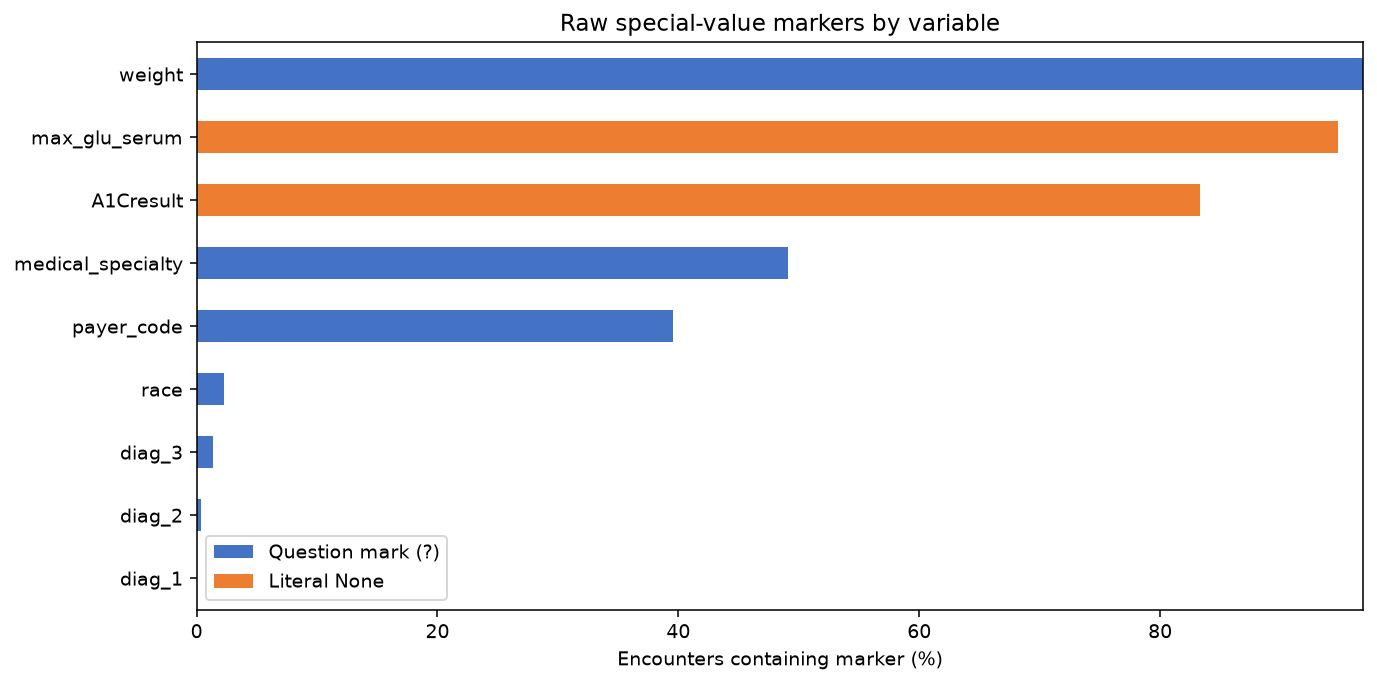

In [3]:
marker_summary = pd.DataFrame(
    {
        "Question mark count": raw_df.eq("?").sum(),
        "Literal None count": raw_df.eq("None").sum(),
        "Blank cell count": raw_df.eq("").sum(),
    }
)
marker_summary = marker_summary.loc[marker_summary.sum(axis=1) > 0].copy()
marker_summary["Question mark (%)"] = marker_summary["Question mark count"].div(len(raw_df)).mul(100)
marker_summary["Literal None (%)"] = marker_summary["Literal None count"].div(len(raw_df)).mul(100)
marker_summary["Total marked cells"] = marker_summary[
    ["Question mark count", "Literal None count", "Blank cell count"]
].sum(axis=1)
marker_summary = marker_summary.sort_values("Total marked cells", ascending=False)
display(marker_summary.round({"Question mark (%)": 2, "Literal None (%)": 2}))

plot_data = marker_summary[["Question mark (%)", "Literal None (%)"]].copy()
plot_data["Total (%)"] = plot_data.sum(axis=1)
plot_data = plot_data.sort_values("Total (%)").drop(columns="Total (%)")
fig, ax = plt.subplots(figsize=(10, 5))
plot_data.plot.barh(stacked=True, ax=ax, color=["#4472C4", "#ED7D31"])
ax.set_title("Raw special-value markers by variable")
ax.set_xlabel("Encounters containing marker (%)")
ax.set_ylabel("")
ax.legend(["Question mark (?)", "Literal None"])
fig.tight_layout()
display(fig)
plt.close(fig)


The CSV contains 192,849 `?` markers, 181,168 literal `None` tokens, and no blank cells. `?` occurs in categorical fields including `weight`, `medical_specialty`, `payer_code`, `race`, and the diagnosis columns. `None` occurs in the two lab-result fields; the UCI documentation says it means the test was not taken, so it is not an ordinary missing lab value.

The largest `?` share is `weight` (96.86%). `medical_specialty` and `payer_code` are also incomplete (49.08% and 39.56%). We will decide how to represent these values below rather than dropping encounters.

## 3. What is the target distribution?

First count the original three labels. Then summarize the planned binary target: `<30` is positive; `>30` and `NO` are negative for the specific objective of early readmission.


,Encounters,Share (%)
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


,Encounters,Share (%)
readmitted,,
Early readmission (<30 days),11357,11.16
No early readmission,90409,88.84


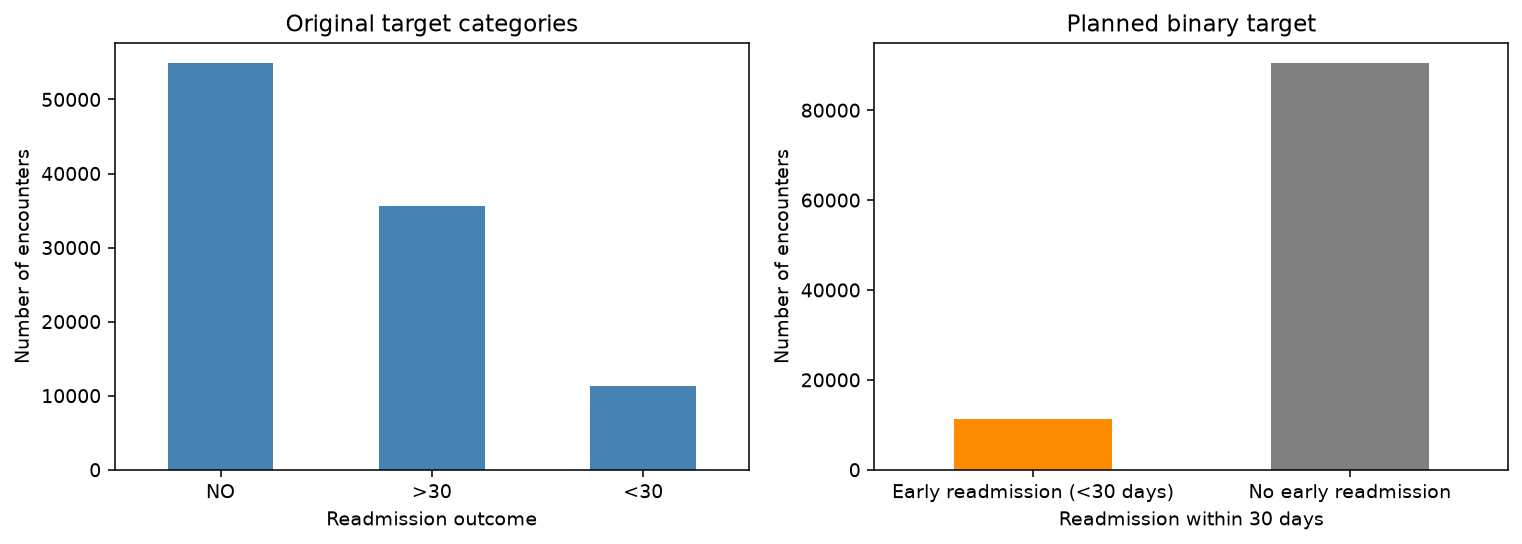

In [4]:
target_order = ["NO", ">30", "<30"]
unexpected_target_values = sorted(set(raw_df["readmitted"].unique()) - set(target_order))
if unexpected_target_values:
    raise ValueError(f"Unexpected readmitted categories: {unexpected_target_values}")

target_counts = raw_df["readmitted"].value_counts().reindex(target_order, fill_value=0)
target_summary = pd.DataFrame(
    {
        "Encounters": target_counts,
        "Share (%)": target_counts.div(len(raw_df)).mul(100),
    }
)
display(target_summary.round(2))

binary_target = raw_df["readmitted"].map(
    {
        "<30": "Early readmission (<30 days)",
        "NO": "No early readmission",
        ">30": "No early readmission",
    }
)
binary_counts = binary_target.value_counts().reindex(
    ["Early readmission (<30 days)", "No early readmission"], fill_value=0
)
binary_summary = pd.DataFrame(
    {"Encounters": binary_counts, "Share (%)": binary_counts.div(len(raw_df)).mul(100)}
)
display(binary_summary.round(2))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4))
target_counts.plot.bar(ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Original target categories")
axes[0].set_xlabel("Readmission outcome")
axes[0].set_ylabel("Number of encounters")
binary_counts.plot.bar(ax=axes[1], color=["darkorange", "gray"], rot=0)
axes[1].set_title("Planned binary target")
axes[1].set_xlabel("Readmission within 30 days")
axes[1].set_ylabel("Number of encounters")
fig.tight_layout()
display(fig)
plt.close(fig)


In the original data, 11,357 encounters (11.16%) have `readmitted = <30`. `>30` is negative for this project because it means the readmission occurred after the 30-day window, not because the patient was never readmitted. These are observed labels, not model predictions.

## 4. Is prior inpatient utilization associated with early readmission?

Compare the rate by the exact `number_inpatient` count. Show encounter counts separately because rates at the high-count tail can be unstable.


,Encounters,Early readmissions (<30 days),Early readmission rate (%)
number_inpatient,,,
0,67630,5706,8.44
1,19521,2523,12.92
2,7566,1319,17.43
3,3411,692,20.29
4,1622,383,23.61


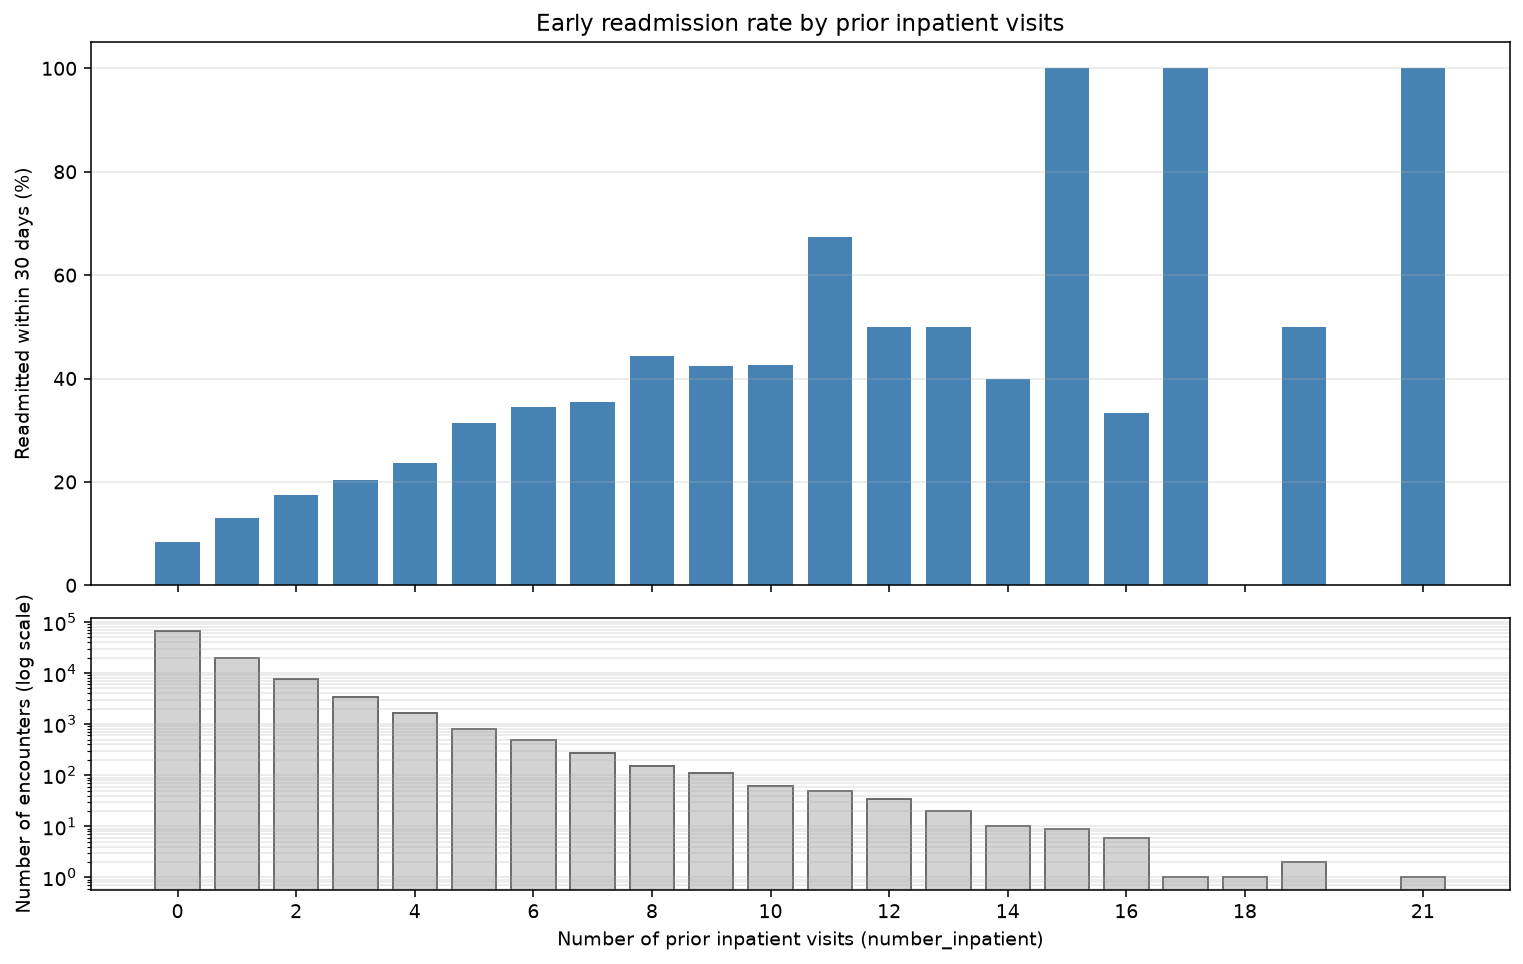

In [5]:
prior_inpatient_data = pd.DataFrame(
    {
        "number_inpatient": raw_df["number_inpatient"],
        "early_readmission": raw_df["readmitted"].eq("<30"),
    }
)
prior_inpatient_summary = prior_inpatient_data.groupby("number_inpatient", sort=True).agg(
    encounters=("early_readmission", "size"),
    early_readmissions=("early_readmission", "sum"),
)
prior_inpatient_summary["early_readmission_rate_pct"] = (
    prior_inpatient_summary["early_readmissions"]
    .div(prior_inpatient_summary["encounters"])
    .mul(100)
)
common_prior_counts = prior_inpatient_summary.loc[prior_inpatient_summary.index <= 4].rename(
    columns={
        "encounters": "Encounters",
        "early_readmissions": "Early readmissions (<30 days)",
        "early_readmission_rate_pct": "Early readmission rate (%)",
    }
)
display(common_prior_counts.round(2))

observed_prior_counts = prior_inpatient_summary.index.to_numpy()
fig, (rate_ax, count_ax) = plt.subplots(
    nrows=2, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
rate_ax.bar(
    observed_prior_counts,
    prior_inpatient_summary["early_readmission_rate_pct"],
    color="steelblue",
    width=0.75,
)
rate_ax.set_title("Early readmission rate by prior inpatient visits")
rate_ax.set_ylabel("Readmitted within 30 days (%)")
rate_ax.set_ylim(0, 105)
rate_ax.grid(axis="y", alpha=0.3)
count_ax.bar(
    observed_prior_counts,
    prior_inpatient_summary["encounters"],
    color="lightgray",
    edgecolor="dimgray",
    width=0.75,
)
count_ax.set_yscale("log")
count_ax.set_ylabel("Number of encounters (log scale)")
count_ax.set_xlabel("Number of prior inpatient visits (number_inpatient)")
ticks = observed_prior_counts[::2]
if observed_prior_counts[-1] not in ticks:
    ticks = list(ticks) + [observed_prior_counts[-1]]
count_ax.set_xticks(ticks)
count_ax.grid(axis="y", which="both", alpha=0.3)
fig.tight_layout()
display(fig)
plt.close(fig)


For common counts, the rate rises from 8.44% with 0 prior inpatient visits to 12.92% with 1, 17.43% with 2, and 20.29% with 3. The high-count tail contains very few encounters, so its extreme percentages are not reliable evidence of a stable trend. This is a descriptive association, not a causal effect.

## 5. Does any prior emergency or outpatient use matter descriptively?

A compact first comparison is 0 versus at least 1 prior visit for each field. The chart labels both the rate and group size.


,Variable,History,Encounters,Early readmissions (<30 days),Early readmission rate (%)
0,Prior emergency visits,No prior visits,90383,9467,10.47
1,Prior emergency visits,At least one prior visit,11383,1890,16.60
2,Prior outpatient visits,No prior visits,85027,9076,10.67
3,Prior outpatient visits,At least one prior visit,16739,2281,13.63


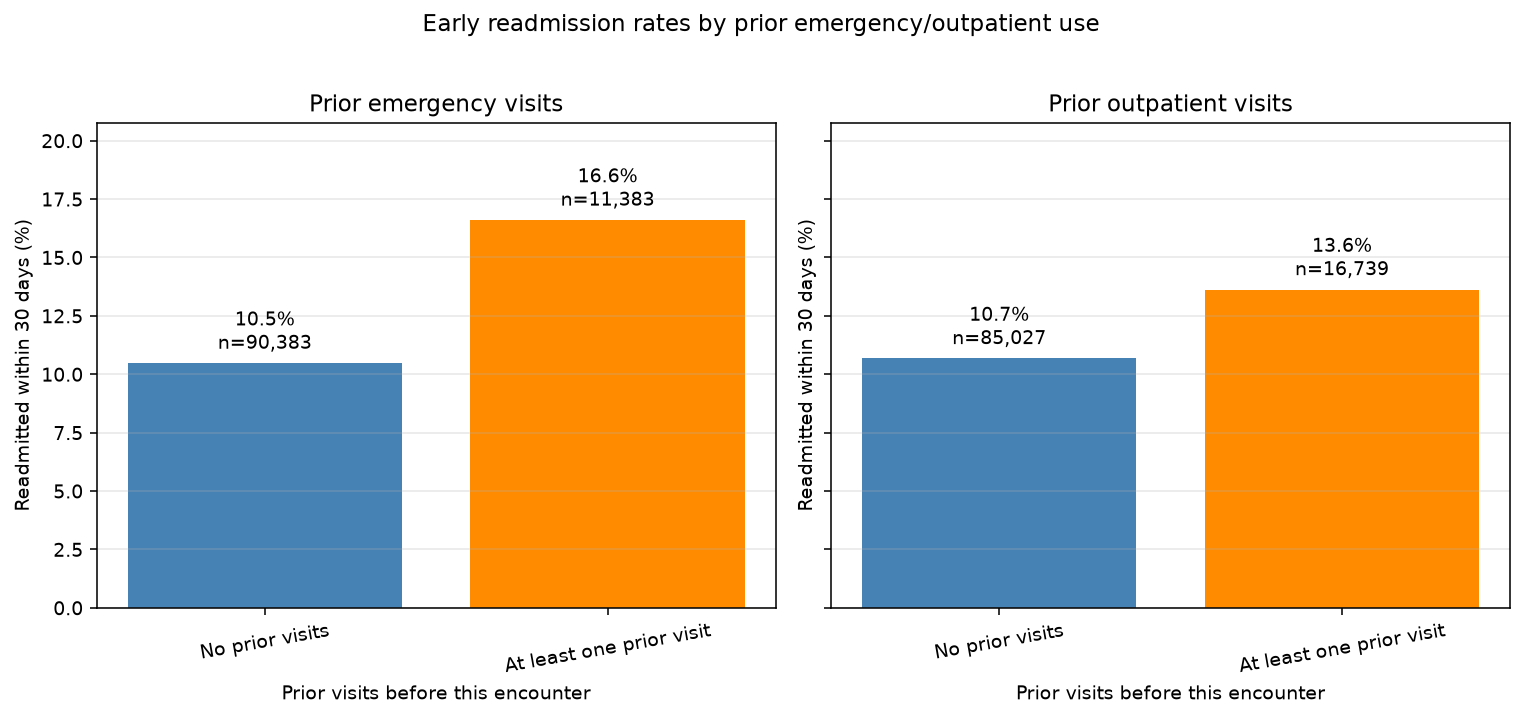

In [6]:
visit_variables = {
    "number_emergency": "Prior emergency visits",
    "number_outpatient": "Prior outpatient visits",
}
early_readmission_flag = raw_df["readmitted"].eq("<30")
visit_rows = []
for variable, label in visit_variables.items():
    has_prior_visit = raw_df[variable].gt(0)
    for had_visit, group_label in [(False, "No prior visits"), (True, "At least one prior visit")]:
        mask = has_prior_visit.eq(had_visit)
        encounters = int(mask.sum())
        early_count = int(early_readmission_flag[mask].sum())
        visit_rows.append(
            {
                "Variable": label,
                "History": group_label,
                "Encounters": encounters,
                "Early readmissions (<30 days)": early_count,
                "Early readmission rate (%)": early_count / encounters * 100,
            }
        )
visit_summary = pd.DataFrame(visit_rows)
display(visit_summary.round({"Early readmission rate (%)": 2}))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 5), sharey=True)
group_order = ["No prior visits", "At least one prior visit"]
for ax, (variable, title) in zip(axes, visit_variables.items()):
    plot_data = (
        visit_summary[visit_summary["Variable"] == title]
        .set_index("History")
        .reindex(group_order)
    )
    bars = ax.bar(
        group_order,
        plot_data["Early readmission rate (%)"],
        color=["steelblue", "darkorange"],
    )
    ax.set_title(title)
    ax.set_ylabel("Readmitted within 30 days (%)")
    ax.set_xlabel("Prior visits before this encounter")
    ax.set_ylim(0, visit_summary["Early readmission rate (%)"].max() * 1.25)
    ax.tick_params(axis="x", labelrotation=10)
    ax.grid(axis="y", alpha=0.3)
    for bar, (_, row) in zip(bars, plot_data.iterrows()):
        ax.annotate(
            f"{row['Early readmission rate (%)']:.1f}%\nn={int(row['Encounters']):,}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
        )
fig.suptitle("Early readmission rates by prior emergency/outpatient use", y=1.02)
fig.tight_layout()
display(fig)
plt.close(fig)


At least one prior emergency visit is associated with a 16.60% early-readmission rate, compared with 10.47% with none. For outpatient visits the rates are 13.63% and 10.67%. These are separate, descriptive comparisons; neither demonstrates causality.

## 6. Do age or gender show clear differences?

Keep the ordered age groups visible. For gender, show the rates and denominators in a table; the `Unknown/Invalid` group is too small to support an interpretation.


,Encounters,Early readmissions (<30 days),Early readmission rate (%)
age,,,
[0-10),161,3,1.86
[10-20),691,40,5.79
[20-30),1657,236,14.24
[30-40),3775,424,11.23
[40-50),9685,1027,10.60
[50-60),17256,1668,9.67
[60-70),22483,2502,11.13
[70-80),26068,3069,11.77
[80-90),17197,2078,12.08


,Encounters,Early readmissions (<30 days),Early readmission rate (%)
gender,,,
Female,54708,6152,11.25
Male,47055,5205,11.06
Unknown/Invalid,3,0,0.00


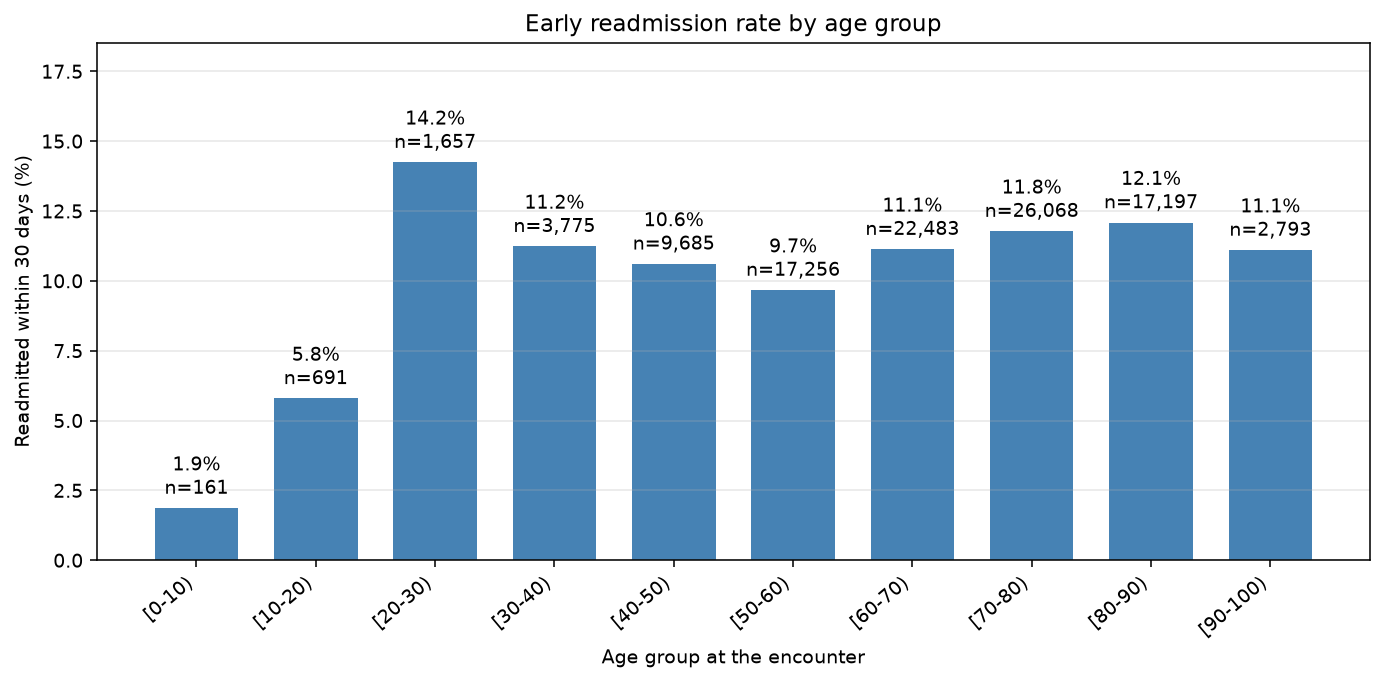

In [7]:
age_order = [f"[{start}-{start + 10})" for start in range(0, 100, 10)]
unexpected_age_groups = sorted(set(raw_df["age"].unique()) - set(age_order))
if unexpected_age_groups:
    raise ValueError(f"Unexpected age groups: {unexpected_age_groups}")
age_data = pd.DataFrame(
    {
        "age": pd.Categorical(raw_df["age"], categories=age_order, ordered=True),
        "early_readmission": raw_df["readmitted"].eq("<30"),
    }
)
age_summary = age_data.groupby("age", observed=True).agg(
    encounters=("early_readmission", "size"),
    early_readmissions=("early_readmission", "sum"),
)
age_summary["early_readmission_rate_pct"] = (
    age_summary["early_readmissions"].div(age_summary["encounters"]).mul(100)
)
display(
    age_summary.rename(
        columns={
            "encounters": "Encounters",
            "early_readmissions": "Early readmissions (<30 days)",
            "early_readmission_rate_pct": "Early readmission rate (%)",
        }
    ).round(2)
)

gender_data = pd.DataFrame(
    {"gender": raw_df["gender"], "early_readmission": raw_df["readmitted"].eq("<30")}
)
gender_summary = gender_data.groupby("gender", sort=False).agg(
    encounters=("early_readmission", "size"),
    early_readmissions=("early_readmission", "sum"),
)
gender_summary["early_readmission_rate_pct"] = (
    gender_summary["early_readmissions"].div(gender_summary["encounters"]).mul(100)
)
display(
    gender_summary.rename(
        columns={
            "encounters": "Encounters",
            "early_readmissions": "Early readmissions (<30 days)",
            "early_readmission_rate_pct": "Early readmission rate (%)",
        }
    ).round(2)
)

fig, ax = plt.subplots(figsize=(10, 5))
age_labels = age_summary.index.astype(str)
bars = ax.bar(
    range(len(age_labels)), age_summary["early_readmission_rate_pct"], color="steelblue", width=0.7
)
ax.set_title("Early readmission rate by age group")
ax.set_ylabel("Readmitted within 30 days (%)")
ax.set_xlabel("Age group at the encounter")
ax.set_xticks(range(len(age_labels)), age_labels, rotation=40, ha="right")
ax.set_ylim(0, age_summary["early_readmission_rate_pct"].max() * 1.3)
ax.grid(axis="y", alpha=0.3)
for bar, (_, row) in zip(bars, age_summary.iterrows()):
    ax.annotate(
        f"{row['early_readmission_rate_pct']:.1f}%\nn={int(row['encounters']):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )
fig.tight_layout()
display(fig)
plt.close(fig)


The age pattern is not steadily increasing: the highest observed rate is 14.24% for ages 20-30; the 50-60 group is at 9.67%. The youngest groups are small (161 encounters for ages 0-10 and 691 for ages 10-20). Female and male encounter rates are similar (11.25% and 11.06%); `Unknown/Invalid` occurs in only three encounters. Keep age/gender/race for analysis, but treat demographics as sensitive and evaluate subgroup performance.

## 7. What do admission and discharge codes show?

Use the mapping file to label numeric IDs as categories. The table shows the five most frequent categories per field; a second table identifies dispositions that affect whether a patient is at risk after discharge.


In [8]:
mapping_path = data_path.with_name("IDS_mapping.csv")
if not mapping_path.is_file():
    raise FileNotFoundError(f"Could not find {mapping_path.name} beside the dataset.")
mapping_raw = pd.read_csv(
    mapping_path,
    header=None,
    names=["code", "description"],
    dtype="string",
    keep_default_na=False,
    skip_blank_lines=False,
)
id_variables = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
section_rows = mapping_raw["code"].isin(id_variables)
mapping_raw["variable"] = mapping_raw["code"].where(section_rows).ffill()
numeric_rows = mapping_raw["code"].str.fullmatch(r"\d+", na=False)
mapping_entries = mapping_raw.loc[numeric_rows].copy()
mapping_entries["id_code"] = mapping_entries["code"].astype(int)
mapping_entries["description"] = mapping_entries["description"].str.strip()

id_labels = {
    "admission_type_id": "Admission type",
    "admission_source_id": "Admission source",
    "discharge_disposition_id": "Discharge disposition",
}
id_rows = []
for variable, label in id_labels.items():
    descriptions = mapping_entries.loc[mapping_entries["variable"] == variable].set_index("id_code")[
        "description"
    ]
    observed_codes = set(raw_df[variable].unique())
    if observed_codes - set(descriptions.index):
        raise ValueError(f"Unmapped observed codes for {variable}: {sorted(observed_codes - set(descriptions.index))}")
    grouped = pd.DataFrame(
        {"code": raw_df[variable], "early": raw_df["readmitted"].eq("<30")}
    ).groupby("code").agg(encounters=("early", "size"), early_readmissions=("early", "sum"))
    grouped["rate"] = grouped["early_readmissions"].div(grouped["encounters"]).mul(100)
    for code, row in grouped.iterrows():
        id_rows.append(
            {
                "Variable": label,
                "Code": int(code),
                "Description": descriptions.loc[code],
                "Encounters": int(row["encounters"]),
                "Early readmissions (<30 days)": int(row["early_readmissions"]),
                "Early readmission rate (%)": row["rate"],
            }
        )
id_category_summary = pd.DataFrame(id_rows).sort_values(
    ["Variable", "Encounters"], ascending=[True, False]
)
display(id_category_summary.groupby("Variable", sort=False).head(5).round({"Early readmission rate (%)": 2}))

discharge_target_counts = pd.crosstab(
    raw_df["discharge_disposition_id"], raw_df["readmitted"]
).reindex(columns=["<30", ">30", "NO"], fill_value=0)
expired_mask = raw_df["discharge_disposition_id"].isin([11, 19, 20])
unclear_discharge_mask = raw_df["discharge_disposition_id"].eq(12)
eligible_discharge_mask = ~(expired_mask | unclear_discharge_mask)
discharge_lookup = mapping_entries.loc[
    mapping_entries["variable"] == "discharge_disposition_id"
].set_index("id_code")["description"]
risk_rows = []
for code in [11, 12, 19, 20]:
    counts = discharge_target_counts.loc[code]
    risk_rows.append(
        {
            "Code": code,
            "Description": discharge_lookup.loc[code],
            "Encounters": int(counts.sum()),
            "<30": int(counts["<30"]),
            ">30": int(counts[">30"]),
            "NO": int(counts["NO"]),
        }
    )
display(pd.DataFrame(risk_rows))

cohort_definitions = {
    "All original encounters": pd.Series(True, index=raw_df.index),
    "Explicitly expired (11, 19, 20)": expired_mask,
    "Not clearly discharged (12)": unclear_discharge_mask,
    "Eligible after provisional exclusions": eligible_discharge_mask,
}
cohort_rows = []
for label, mask in cohort_definitions.items():
    counts = raw_df.loc[mask, "readmitted"].value_counts().reindex(["<30", ">30", "NO"], fill_value=0)
    encounters = int(mask.sum())
    positive_count = int(counts["<30"])
    cohort_rows.append(
        {
            "Cohort": label,
            "Encounters": encounters,
            "Early readmissions (<30 days)": positive_count,
            "Early readmission rate (%)": positive_count / encounters * 100 if encounters else 0,
        }
    )
cohort_summary = pd.DataFrame(cohort_rows)
if int(expired_mask.sum()) != 1652 or int(unclear_discharge_mask.sum()) != 3:
    raise ValueError("Discharge eligibility counts changed; review the cohort rule.")
if int(eligible_discharge_mask.sum()) != 100111:
    raise ValueError("The provisional eligible-cohort size differs from the verified count.")
display(cohort_summary.round({"Early readmission rate (%)": 2}))


,Variable,Code,Description,Encounters,Early readmissions (<30 days),Early readmission rate (%)
14,Admission source,7,Emergency Room,57494,6720,11.69
8,Admission source,1,Physician Referral,29565,3130,10.59
21,Admission source,17,NULL,6781,706,10.41
11,Admission source,4,Transfer from a hospital,3187,309,9.70
13,Admission source,6,Transfer from another health care facility,2264,212,9.36
0,Admission type,1,Emergency,53990,6221,11.52
2,Admission type,3,Elective,18869,1961,10.39
1,Admission type,2,Urgent,18480,2066,11.18
5,Admission type,6,NULL,5291,586,11.08
4,Admission type,5,Not Available,4785,495,10.34


,Code,Description,Encounters,<30,>30,NO
0,11,Expired,1642,0,0,1642
1,12,Still patient or expected to return for outpatient services,3,2,0,1
2,19,"Expired at home. Medicaid only, hospice.",8,0,0,8
3,20,"Expired in a medical facility. Medicaid only, hospice.",2,0,0,2


,Cohort,Encounters,Early readmissions (<30 days),Early readmission rate (%)
0,All original encounters,101766,11357,11.16
1,"Explicitly expired (11, 19, 20)",1652,0,0.00
2,Not clearly discharged (12),3,2,66.67
3,Eligible after provisional exclusions,100111,11355,11.34


The most frequent discharge destinations are home, skilled nursing facilities, and home with health services. Their observed early-readmission rates differ, but these comparisons are descriptive and category denominators matter.

The mapping identifies 1,652 encounters with explicit expired dispositions (codes 11, 19, and 20), all labelled `NO`, and 3 records with code 12 (`Still patient or expected to return for outpatient services`), including 2 `<30` labels. For a discharge-time readmission task, provisionally exclude both groups because they do not represent a clear at-risk completed discharge. Keep hospice codes 13 and 14: early readmissions occur in those groups. This leaves 100,111 encounters and 11,355 positive examples. The raw dataset is unchanged; the eligibility mask is only a cohort proposal.

## 8. Are diagnosis fields usable as categorical features?

Summarize cardinality, `?` counts, and the most frequent diagnosis codes. Do not treat diagnosis codes as numeric magnitudes.


In [9]:
diagnosis_variables = ["diag_1", "diag_2", "diag_3"]
diagnosis_profile_rows = []
top_diagnosis_rows = []
early_flag = raw_df["readmitted"].eq("<30")
for variable in diagnosis_variables:
    observed_mask = raw_df[variable].ne("?")
    observed_codes = raw_df.loc[observed_mask, variable]
    diagnosis_profile_rows.append(
        {
            "Variable": variable,
            "Distinct observed codes": observed_codes.nunique(),
            "Question-mark values": int(raw_df[variable].eq("?").sum()),
        }
    )
    diagnosis_data = pd.DataFrame(
        {"code": observed_codes, "early": early_flag.loc[observed_mask]}
    )
    grouped = diagnosis_data.groupby("code").agg(
        encounters=("early", "size"), early_readmissions=("early", "sum")
    )
    grouped["rate"] = grouped["early_readmissions"].div(grouped["encounters"]).mul(100)
    for code, row in grouped.nlargest(5, "encounters").iterrows():
        top_diagnosis_rows.append(
            {
                "Variable": variable,
                "Code": code,
                "Encounters": int(row["encounters"]),
                "Early readmissions (<30 days)": int(row["early_readmissions"]),
                "Early readmission rate (%)": row["rate"],
            }
        )
diagnosis_profile = pd.DataFrame(diagnosis_profile_rows)
top_diagnoses = pd.DataFrame(top_diagnosis_rows)
display(diagnosis_profile)
display(top_diagnoses.round({"Early readmission rate (%)": 2}))


,Variable,Distinct observed codes,Question-mark values
0,diag_1,716,21
1,diag_2,748,358
2,diag_3,789,1423


,Variable,Code,Encounters,Early readmissions (<30 days),Early readmission rate (%)
0,diag_1,428,6862,968,14.11
1,diag_1,414,6581,595,9.04
2,diag_1,786,4016,291,7.25
3,diag_1,410,3614,373,10.32
4,diag_1,486,3508,314,8.95
5,diag_2,276,6752,810,12.00
6,diag_2,428,6662,842,12.64
7,diag_2,250,6071,446,7.35
8,diag_2,427,5036,563,11.18
9,diag_2,401,3736,268,7.17


The three diagnosis fields contain 716, 748, and 789 observed codes, with only 21, 358, and 1,423 `?` values. Keep them as categorical candidates; their high cardinality means rare-level handling or a clinically validated code grouping may be needed. Learn any rare-level grouping on training data only.

## 9. What do the lab-result categories mean?

The UCI documentation explicitly defines `None` in `max_glu_serum` and `A1Cresult` as a test that was not taken. Compare outcomes by the recorded category while retaining that distinction.


,Test,Recorded category,Encounters,Early readmissions (<30 days),Early readmission rate (%)
0,Maximum glucose test,Not measured,96420,10696,11.09
1,Maximum glucose test,Normal,2597,295,11.36
2,Maximum glucose test,>200,1485,185,12.46
3,Maximum glucose test,>300,1264,181,14.32
4,HbA1c test,Not measured,84748,9681,11.42
5,HbA1c test,Normal,4990,482,9.66
6,HbA1c test,>7,3812,383,10.05
7,HbA1c test,>8,8216,811,9.87


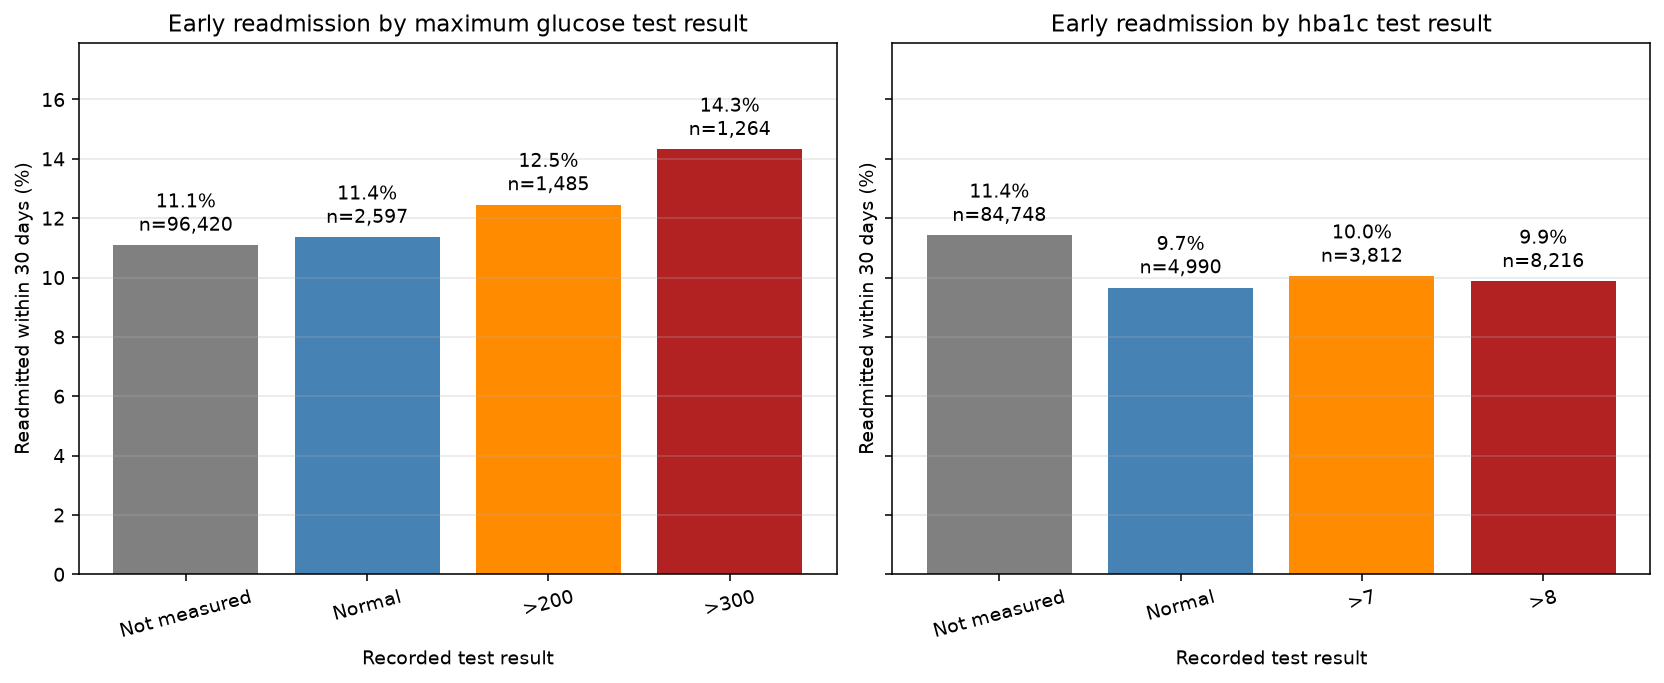

In [10]:
lab_variables = {
    "max_glu_serum": {"label": "Maximum glucose test", "order": ["None", "Norm", ">200", ">300"]},
    "A1Cresult": {"label": "HbA1c test", "order": ["None", "Norm", ">7", ">8"]},
}
lab_display_labels = {"None": "Not measured", "Norm": "Normal"}
lab_rows = []
for variable, settings in lab_variables.items():
    unexpected = sorted(set(raw_df[variable].unique()) - set(settings["order"]))
    if unexpected:
        raise ValueError(f"Unexpected values for {variable}: {unexpected}")
    grouped = pd.DataFrame(
        {"result": raw_df[variable], "early": raw_df["readmitted"].eq("<30")}
    ).groupby("result", sort=False).agg(
        encounters=("early", "size"), early_readmissions=("early", "sum")
    )
    grouped["rate"] = grouped["early_readmissions"].div(grouped["encounters"]).mul(100)
    for result in settings["order"]:
        row = grouped.loc[result]
        lab_rows.append(
            {
                "Test": settings["label"],
                "Recorded category": lab_display_labels.get(result, result),
                "Encounters": int(row["encounters"]),
                "Early readmissions (<30 days)": int(row["early_readmissions"]),
                "Early readmission rate (%)": row["rate"],
            }
        )
lab_summary = pd.DataFrame(lab_rows)
display(lab_summary.round({"Early readmission rate (%)": 2}))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), sharey=True)
ymax = lab_summary["Early readmission rate (%)"].max() * 1.25
for ax, (variable, settings) in zip(axes, lab_variables.items()):
    label = settings["label"]
    plot_data = lab_summary[lab_summary["Test"] == label].set_index("Recorded category")
    ordered = [lab_display_labels.get(value, value) for value in settings["order"]]
    plot_data = plot_data.reindex(ordered)
    bars = ax.bar(
        plot_data.index,
        plot_data["Early readmission rate (%)"],
        color=["gray", "steelblue", "darkorange", "firebrick"],
    )
    ax.set_title(f"Early readmission by {label.lower()} result")
    ax.set_ylabel("Readmitted within 30 days (%)")
    ax.set_xlabel("Recorded test result")
    ax.set_ylim(0, ymax)
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", alpha=0.3)
    for bar, (_, row) in zip(bars, plot_data.iterrows()):
        ax.annotate(
            f"{row['Early readmission rate (%)']:.1f}%\nn={int(row['Encounters']):,}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
        )
fig.tight_layout()
display(fig)
plt.close(fig)


`Not measured` represents 94.75% of maximum-glucose records and 83.28% of HbA1c records. Keep it as a category, not an imputed test result. The measured categories are less common, and their observed rate differences are descriptive; retain both test fields as candidates for now.

## 10. Which medication fields vary?

The medication features use categorical statuses (`No`, `Steady`, `Up`, `Down`). Summarize the most frequently non-`No` medications and identify constant fields instead of displaying a long table of mostly repeated values.


,Medication,Observed statuses,No,Steady,Up,Down,Non-No encounters
1,repaglinide,4,100227,1384,110,45,1539
4,glimepiride,4,96575,4670,327,194,5191
10,rosiglitazone,4,95401,6100,178,87,6365
9,pioglitazone,4,94438,6976,234,118,7328
7,glyburide,4,91116,9274,812,564,10650
6,glipizide,4,89080,11356,770,560,12686
0,metformin,4,81778,18346,1067,575,19988
17,insulin,4,47383,30849,11316,12218,54383


,Constant medication fields
0,examide
1,citoglipton


,Variable,Category counts
0,change,"{'No': 54755, 'Ch': 47011}"
1,diabetesMed,"{'Yes': 78363, 'No': 23403}"


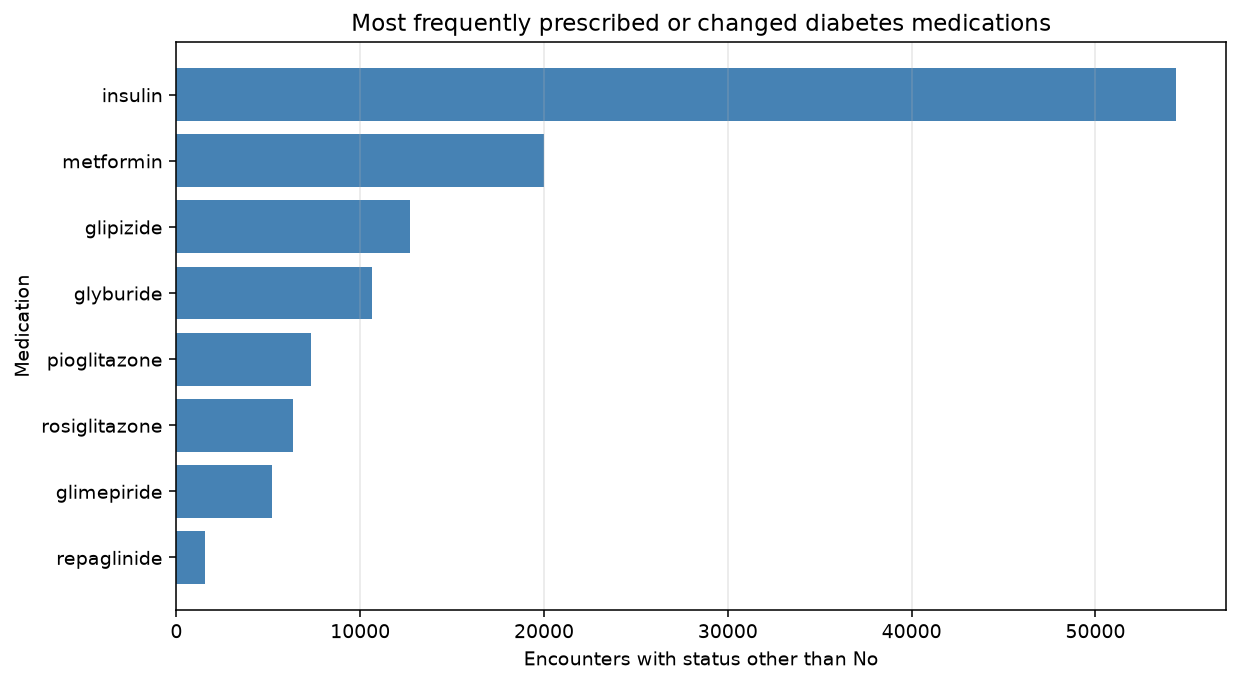

In [11]:
medication_variables = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
    "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
    "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
status_order = ["No", "Steady", "Up", "Down"]
medication_rows = []
for variable in medication_variables:
    counts = raw_df[variable].value_counts().reindex(status_order, fill_value=0)
    medication_rows.append(
        {
            "Medication": variable,
            "Observed statuses": int(raw_df[variable].nunique()),
            "No": int(counts["No"]),
            "Steady": int(counts["Steady"]),
            "Up": int(counts["Up"]),
            "Down": int(counts["Down"]),
            "Non-No encounters": int(len(raw_df) - counts["No"]),
        }
    )
medication_summary = pd.DataFrame(medication_rows)
constant_medications = medication_summary.loc[
    medication_summary["Observed statuses"] == 1, "Medication"
].tolist()
top_medications = (
    medication_summary.loc[medication_summary["Non-No encounters"] > 0]
    .nlargest(8, "Non-No encounters")
    .sort_values("Non-No encounters")
)
display(top_medications)
display(pd.DataFrame({"Constant medication fields": constant_medications}))
medication_context = pd.DataFrame(
    [
        {"Variable": variable, "Category counts": raw_df[variable].value_counts().to_dict()}
        for variable in ["change", "diabetesMed"]
    ]
)
display(medication_context)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_medications["Medication"], top_medications["Non-No encounters"], color="steelblue")
ax.set_title("Most frequently prescribed or changed diabetes medications")
ax.set_xlabel("Encounters with status other than No")
ax.set_ylabel("Medication")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
display(fig)
plt.close(fig)


The medication fields are categorical, not numerical doses. `examide` and `citoglipton` have only the `No` value in all 101,766 encounters; exclude them because they cannot distinguish records. Keep other non-constant medications as candidates; handle very rare categories in training-only preprocessing.

## Provisional missing-value and feature decisions

| Evidence | Initial decision |
| --- | --- |
| `?` in categorical fields (`race`, `payer_code`, `medical_specialty`, `diag_1`-`diag_3`) | Preserve encounters and encode as an explicit `Unknown` category in preprocessing. |
| `weight` has `?` in 96.86% of encounters | Leave it out of the first candidate set rather than imputing a feature with very little observed data; revisit with a sensitivity comparison. |
| Lab `None` means the test was not taken, per the [UCI variable descriptions](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) | Keep as `Not measured`, not as an ordinary missing result. |
| Mapped ID descriptions include `NULL`, `Not Available`, and `Not Mapped` | Retain these as categorical levels; the IDs are not ordinal measurements and observed codes all have mappings. |
| `gender = Unknown/Invalid` has only 3 encounters | Retain the category, but do not infer a rate from it. |
| Rare diagnosis, code, or medication levels | If grouped into `Other`, learn the grouping from the training split only. |

Retain `payer_code` and `medical_specialty` as candidates with an `Unknown` category despite their 39.56% and 49.08% `?` rates; compare models with and without them. No raw values are changed in this notebook.


## Prediction-time audit and initial candidate set

The intended prediction point is **after the encounter's discharge disposition has been assigned**. According to the [UCI dataset description](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008), the outpatient, emergency, and inpatient counts refer to the year before the encounter, while `readmitted` is the post-discharge outcome.

| Information group | Examples | Availability and use |
| --- | --- | --- |
| Identifiers | `encounter_id`, `patient_nbr` | Exclude from `X`; use `patient_nbr` only to group encounters during train/test splitting. |
| Target | `readmitted` | Outcome after discharge; use only as `y`. |
| Demographics | `age`, `gender`, `race` | Candidate information; these are sensitive attributes, so report subgroup performance and compare with/without race. |
| Prior-year history | `number_inpatient`, `number_emergency`, `number_outpatient` | Documented as counts from the preceding year; candidate predictors. |
| Admission fields | `admission_type_id`, `admission_source_id`, `medical_specialty` | Known at or near admission; categorical candidates. |
| Current-encounter fields | Diagnoses, lab results, medication status, procedures, counts, length of stay | Plausible inputs by discharge. The file has no event timestamps, so exact availability before the prediction moment cannot be proven from this dataset alone. |
| Discharge field | `discharge_disposition_id` | Known only after assignment; include only because prediction is defined after that point. |

For the first modeling cohort, provisionally exclude explicit expired dispositions (codes 11, 19, 20) and code 12 (`Still patient or expected to return for outpatient services`), which does not clearly represent a completed discharge. Keep the original `raw_df` and apply `eligible_discharge_mask` only when building the modeling data. This leaves 100,111 encounters and 11,355 early-readmission cases (11.34%).

### Initial feature shortlist

- **Exclude from `X`:** `encounter_id`, `patient_nbr`, and `readmitted`; keep `patient_nbr` separately for patient-grouped splitting.
- **Exclude initially:** `weight`, `examide`, and `citoglipton`.
- **Retain as candidates:** other demographics, admission/discharge categories, prior-utilization counts, diagnosis fields, lab categories (including `Not measured`), and non-constant medication fields.
- **Evaluate through ablation:** `payer_code` and `medical_specialty`; compare a model with and without `race` and report subgroup metrics.

The next phase is to build a separate modeling dataset, create a patient-grouped train/test split, fit preprocessing on the training data only, and establish a simple baseline. No model has been trained yet.
